--- TABELA: CHUVA x CASOS (2024) ---
   Data  Chuva_Acumulada_mm  Total_Casos
2024-01             2724.63            8
2024-02             4233.57           62
2024-03             2469.25           90
2024-04             2970.36           69
2024-05             6263.53           31
2024-06             8209.87           52
2024-07             3640.24           34
2024-08             2480.05           40
2024-09             1173.71           22
2024-10              673.84           30
2024-11              164.61           22
2024-12              377.72           15
  TOTAL            35381.38          475


--- TABELA: CHUVA x CASOS (2025) ---
   Data  Chuva_Acumulada_mm  Total_Casos
2025-01             2515.43          635
2025-02             2643.70          654
2025-03             1596.07          782
2025-04              687.57          758
2025-05             3882.29          535
2025-06             3174.85          635
2025-07             2161.05          948
2025-08             17

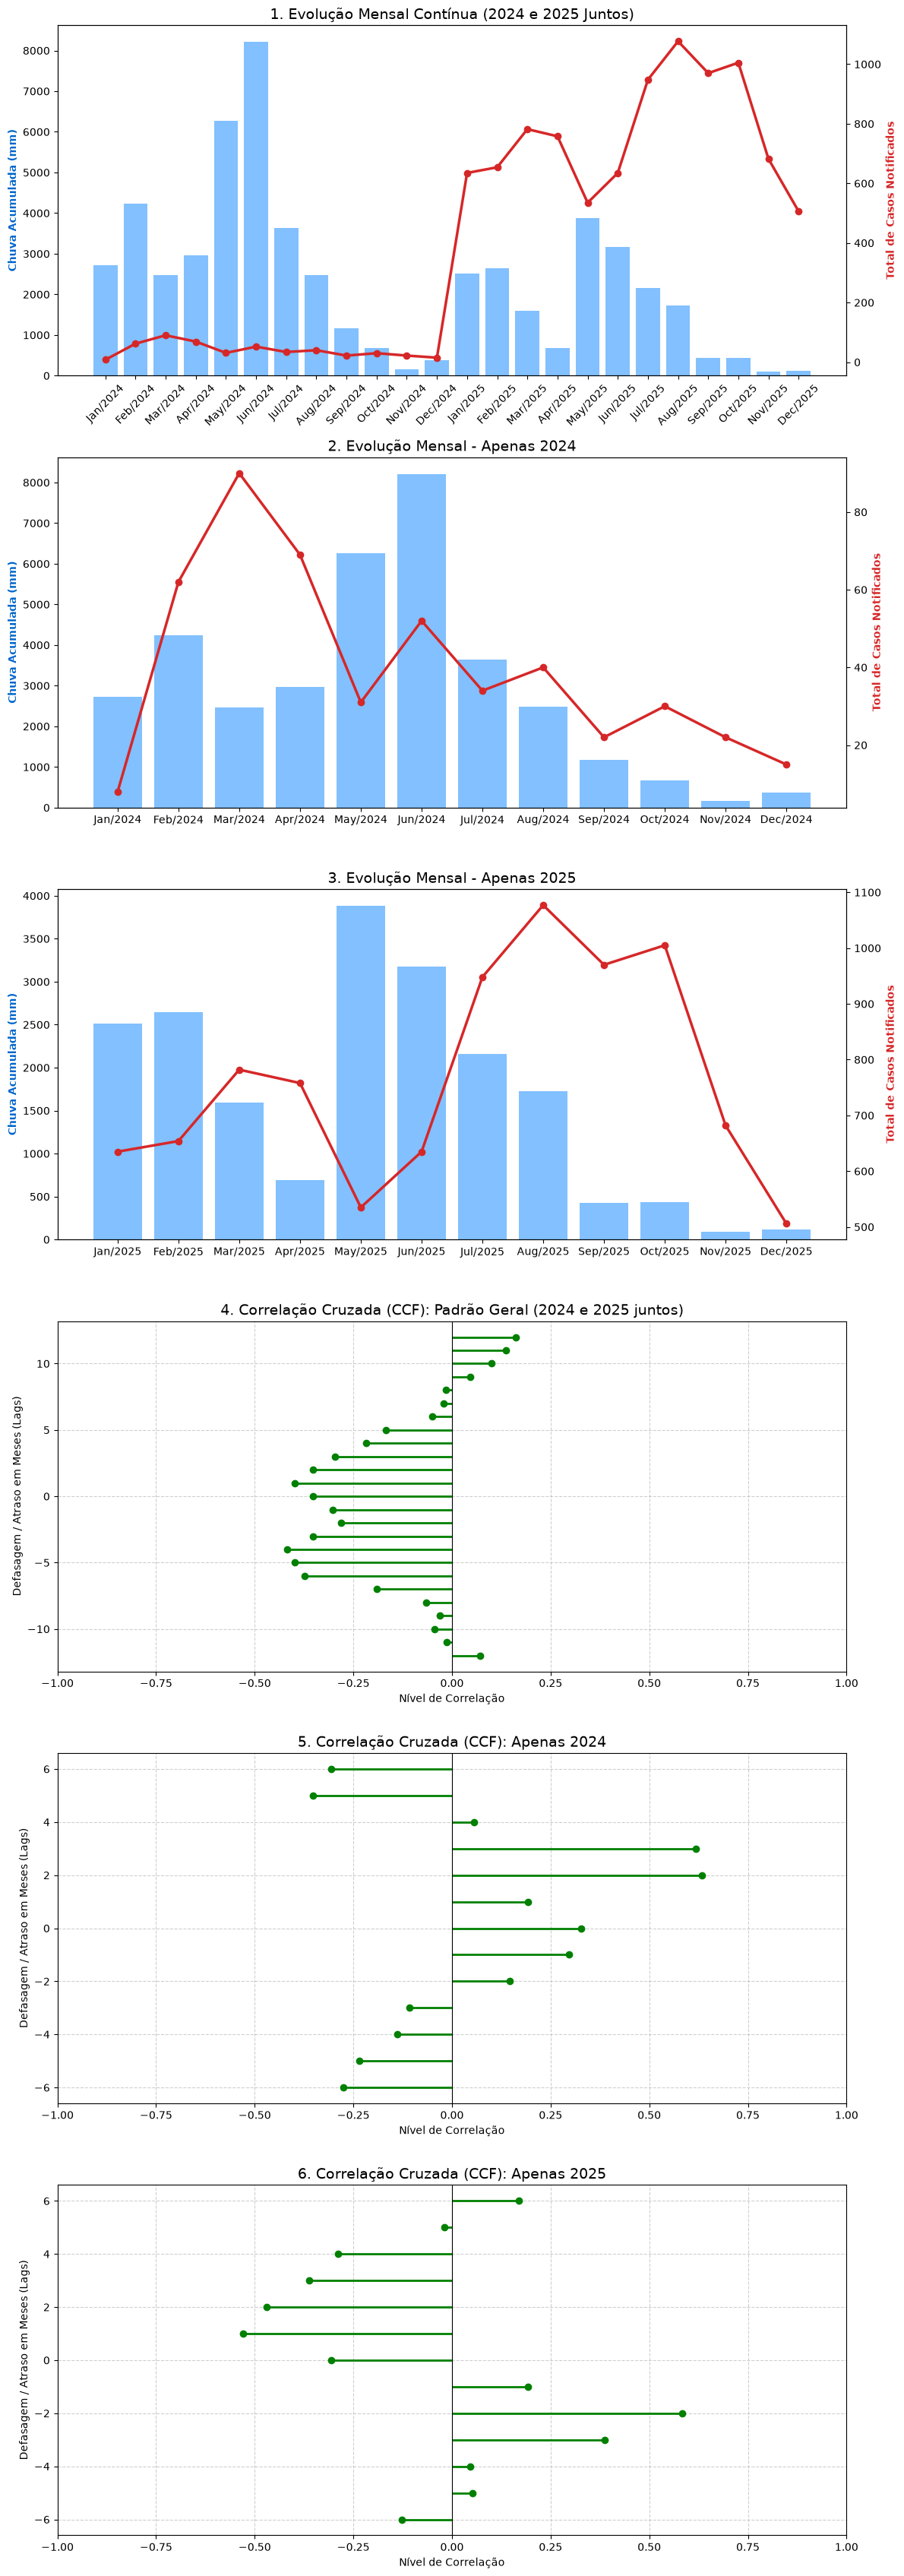

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_chuva_2024 = pd.read_excel('historico_pluvio_mensal_01_01_2024_a_31_12_2025.xlsx')
df_chuva_2025 = pd.read_excel('historico_pluvio_mensal_01_01_2025_a_31_12_2025.xlsx')
df_chuva = pd.concat([df_chuva_2024, df_chuva_2025], ignore_index=True)

df_casos_2024 = pd.read_csv('a5bd9a51-57a3-48f4-bdc5-3af350bbc809.csv', sep=',', low_memory=False, usecols=['DT_NOTIFIC', 'ID_AGRAVO'])
df_casos_2025 = pd.read_csv('45a675e2-d387-4019-bb6e-4b915b74b1bf.csv', sep=',', low_memory=False, usecols=['DT_NOTIFIC', 'ID_AGRAVO'])

df_casos = pd.concat([df_casos_2024, df_casos_2025], ignore_index=True)
df_casos['Data_Notificacao'] = pd.to_datetime(df_casos['DT_NOTIFIC'], format='mixed', errors='coerce')

# Opcional: descomente a linha abaixo se quiser garantir apenas Dengue (A90)
# df_casos = df_casos[df_casos['ID_AGRAVO'] == 'A90']

casos_mensais = df_casos.set_index('Data_Notificacao').resample('MS').size().rename('Total_Casos')

df_chuva_recife = df_chuva[df_chuva['Município'] == 'Recife'].copy()
meses = {'Janeiro': 1, 'Fevereiro': 2, 'Março': 3, 'Abril': 4, 'Maio': 5, 'Junho': 6,
         'Julho': 7, 'Agosto': 8, 'Setembro': 9, 'Outubro': 10, 'Novembro': 11, 'Dezembro': 12}
chuva_long = df_chuva_recife.melt(id_vars=['Ano'], value_vars=meses.keys(), var_name='Mes_Nome', value_name='Precipitacao')
chuva_long['Precipitacao'] = pd.to_numeric(chuva_long['Precipitacao'].astype(str).str.replace(',', '.'), errors='coerce')
chuva_long['Mes'] = chuva_long['Mes_Nome'].map(meses)
chuva_long['Data'] = pd.to_datetime(chuva_long['Ano'].astype(str) + '-' + chuva_long['Mes'].astype(str) + '-01')
chuva_mensal = chuva_long.groupby('Data')['Precipitacao'].sum().rename('Chuva_Acumulada_mm')

df_grafico = pd.concat([chuva_mensal, casos_mensais], axis=1).dropna()
df_grafico['Ano'] = df_grafico.index.year

def imprimir_tabela_ano(df_ano, ano_titulo):
    df_tab = df_ano[['Chuva_Acumulada_mm', 'Total_Casos']].reset_index().rename(columns={'index': 'Data'})
    df_tab['Data'] = df_tab['Data'].dt.strftime('%Y-%m')
    
    total_chuva = df_tab['Chuva_Acumulada_mm'].sum()
    total_casos = df_tab['Total_Casos'].sum()
    linha_total = pd.DataFrame([{'Data': 'TOTAL', 'Chuva_Acumulada_mm': total_chuva, 'Total_Casos': total_casos}])
    df_tab = pd.concat([df_tab, linha_total], ignore_index=True)
    
    print(f"--- TABELA: CHUVA x CASOS ({ano_titulo}) ---")
    print(df_tab.to_string(index=False, max_rows=None))
    print("\n" + "="*50 + "\n")

df_2024 = df_grafico[df_grafico['Ano'] == 2024]
df_2025 = df_grafico[df_grafico['Ano'] == 2025]
imprimir_tabela_ano(df_2024, "2024")
imprimir_tabela_ano(df_2025, "2025")

# 6. PLOTAR OS GRÁFICOS (6 Gráficos no total)
fig, axs = plt.subplots(6, 1, figsize=(12, 34))

# --- Gráfico 1: Sazonalidade Contínua (2024 e 2025 Juntos) ---
meses_str_all = df_grafico.index.strftime('%b/%Y')
axs[0].bar(meses_str_all, df_grafico['Chuva_Acumulada_mm'], color='#4da6ff', alpha=0.7, label='Chuva (mm)')
axs[0].set_ylabel('Chuva Acumulada (mm)', color='#0066cc', fontweight='bold')
axs[0].tick_params(axis='x', rotation=45)
ax1_twin = axs[0].twinx()
ax1_twin.plot(meses_str_all, df_grafico['Total_Casos'], color='#d62728', marker='o', linewidth=2.5, label='Casos')
ax1_twin.set_ylabel('Total de Casos Notificados', color='#d62728', fontweight='bold')
axs[0].set_title('1. Evolução Mensal Contínua (2024 e 2025 Juntos)', fontsize=14)

# --- Gráfico 2: Sazonalidade Apenas 2024 ---
meses_str_2024 = df_2024.index.strftime('%b/%Y')
axs[1].bar(meses_str_2024, df_2024['Chuva_Acumulada_mm'], color='#4da6ff', alpha=0.7, label='Chuva (mm)')
axs[1].set_ylabel('Chuva Acumulada (mm)', color='#0066cc', fontweight='bold')
ax2_twin = axs[1].twinx()
ax2_twin.plot(meses_str_2024, df_2024['Total_Casos'], color='#d62728', marker='o', linewidth=2.5, label='Casos')
ax2_twin.set_ylabel('Total de Casos Notificados', color='#d62728', fontweight='bold')
axs[1].set_title('2. Evolução Mensal - Apenas 2024', fontsize=14)

# --- Gráfico 3: Sazonalidade Apenas 2025 ---
meses_str_2025 = df_2025.index.strftime('%b/%Y')
axs[2].bar(meses_str_2025, df_2025['Chuva_Acumulada_mm'], color='#4da6ff', alpha=0.7, label='Chuva (mm)')
axs[2].set_ylabel('Chuva Acumulada (mm)', color='#0066cc', fontweight='bold')
ax3_twin = axs[2].twinx()
ax3_twin.plot(meses_str_2025, df_2025['Total_Casos'], color='#d62728', marker='o', linewidth=2.5, label='Casos')
ax3_twin.set_ylabel('Total de Casos Notificados', color='#d62728', fontweight='bold')
axs[2].set_title('3. Evolução Mensal - Apenas 2025', fontsize=14)

def plot_ccf_horizontal(ax, df_fonte, max_lags, titulo):
    if len(df_fonte) < 2:
        ax.set_title(f"{titulo} (Dados insuficientes)")
        return

    x = df_fonte['Chuva_Acumulada_mm'].to_numpy(dtype=float)
    y = df_fonte['Total_Casos'].to_numpy(dtype=float)

    x_c = x - x.mean()
    y_c = y - y.mean()

    denominador = np.sqrt(np.sum(x_c**2) * np.sum(y_c**2))
    if denominador == 0:
        ax.set_title(f"{titulo} (Sem variação nos dados)")
        return

    max_lags = min(max_lags, len(x) - 1)

    full_corr = np.correlate(x_c, y_c, mode='full') / denominador
    mid = len(x) - 1
    lags = np.arange(-max_lags, max_lags + 1)
    c = full_corr[mid - max_lags : mid + max_lags + 1]

    ax.hlines(lags, 0, c, colors='green', linewidth=2)
    ax.plot(c, lags, 'go')
    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel('Defasagem / Atraso em Meses (Lags)')
    ax.set_xlabel('Nível de Correlação')
    ax.set_xlim(-1, 1)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.axvline(0, color='black', linewidth=0.8)

# --- Gráfico 4: CCF Conjunto ---
plot_ccf_horizontal(axs[3], df_grafico, 12, '4. Correlação Cruzada (CCF): Padrão Geral (2024 e 2025 juntos)')

# --- Gráfico 5: CCF 2024 ---
plot_ccf_horizontal(axs[4], df_2024, 6, '5. Correlação Cruzada (CCF): Apenas 2024')

# --- Gráfico 6: CCF 2025 ---
plot_ccf_horizontal(axs[5], df_2025, 6, '6. Correlação Cruzada (CCF): Apenas 2025')

plt.tight_layout()
plt.show()